# Time-dependent ROC

A ROC curve measures how well a score separates two groups. In survival analysis the groups change with time: at a time $t$, the "cases" are the individuals who have died by $t$ and the "controls" the ones still alive. For each cut-off $c$ of the risk score $\hat\eta$,

$$
\text{sensitivity}(c,t)=P(\hat\eta>c\mid T\leq t)=\frac{\{1-S(t\mid\hat\eta>c)\}\,P(\hat\eta>c)}{1-S(t)},\qquad
\text{specificity}(c,t)=P(\hat\eta\leq c\mid T>t)=\frac{S(t\mid\hat\eta\leq c)\,P(\hat\eta\leq c)}{S(t)}.
$$

Because of the censoring we do not know who is a case at time $t$, so the survivor functions are estimated with the Kaplan-Meier estimator: of all the individuals, of those above the cut-off, and of those below it.

The data are the survival times, in months, of 48 patients with multiple myeloma, and the risk score comes from the Cox model with bun and hb.

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.metrics import auc
from lifelines import KaplanMeierFitter, CoxPHFitter
from ipywidgets import interact, IntSlider

In [2]:
# Colors shared by all the plots
point_color = '#c1121f'
line_color  = '#1f4e79'
opt_color   = '#E69F00'
ref_color   = '#333333'
CLASS_COLORS = ['#0072B2', '#E69F00', '#009E73', '#D55E00']

## The data and the model

In [3]:
DatOriginal = pd.read_csv("data/multiple_myeloma_survival.dat", sep=r"\s+")
DatOriginal = DatOriginal.drop('patient', axis=1)

In [4]:
Model = CoxPHFitter().fit(DatOriginal, "time", "status", formula="bun+hb")
LogPartialHazard = Model.predict_log_partial_hazard(DatOriginal)
RiskScores = LogPartialHazard.sort_values()

KM = KaplanMeierFitter()
KM.fit(DatOriginal['time'], DatOriginal['status'])

<lifelines.KaplanMeierFitter:"KM_estimate", fitted with 48 total observations, 12 right-censored observations>

## The ROC curve at a time $t$

Every risk score but the largest is used as a cut-off. The estimates can fall slightly outside $[0,1]$, since they combine three Kaplan-Meier estimators, and are then set to 0 or 1. The curve is completed with the points (0, 0) and (1, 1), which correspond to cut-offs above and below all the risk scores. The curves obtained in this way are not always increasing; it is a known limitation of this estimator.

In [5]:
def TimeDependROC(t):
    sens_list = []
    spec_list = []

    for c in RiskScores[:-1]:

        Dat1 = DatOriginal[LogPartialHazard>c]
        km1 = KaplanMeierFitter()
        km1.fit(Dat1['time'], Dat1['status'])

        Dat2 = DatOriginal[LogPartialHazard<=c]
        km2 = KaplanMeierFitter()
        km2.fit(Dat2['time'], Dat2['status'])

        p = len(Dat2) / len(DatOriginal)
        Surv_t = KM.survival_function_at_times(t)

        sens = (1 - km1.survival_function_at_times(t)) * (1-p) / (1-Surv_t)
        spec = km2.survival_function_at_times(t) * p / Surv_t

        sens_list.append(sens.values[0])
        spec_list.append(spec.values[0])

    # Cut-offs above and below all the risk scores
    sens_list = np.array([0] + sens_list + [1])
    spec_list = np.array([1] + spec_list + [0])

    roc = pd.DataFrame({'Sens': sens_list, 'Spec':spec_list})

    roc.loc[roc['Sens']<0, 'Sens'] = 0
    roc.loc[roc['Sens']>1, 'Sens'] = 1

    roc.loc[roc['Spec']<0, 'Spec'] = 0
    roc.loc[roc['Spec']>1, 'Spec'] = 1

    roc['1-Spec'] = 1-roc['Spec']
    roc = roc.sort_values(['1-Spec', 'Sens']).reset_index(drop=True)

    return roc

In [6]:
def PlotRoc(ax, t, color=line_color, label=None, fill=False):
    Roc = TimeDependROC(t)
    area = auc(Roc['1-Spec'], Roc['Sens'])
    if fill:
        ax.fill_between(Roc['1-Spec'], Roc['Sens'], color='#cfe8f3', label=f'Area under the curve = {area:.3f}')
    ax.plot(Roc['1-Spec'], Roc['Sens'], color=color, lw=2, label=label.format(t=t, auc=area) if label else None)
    return area

def FormatRoc(ax, title):
    ax.plot([0,1], [0,1], color=ref_color, lw=1, ls='--', label='No discrimination')
    ax.set_xlabel('1 - specificity')
    ax.set_ylabel('Sensitivity')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.01)
    ax.set_aspect('equal')
    ax.set_title(title)
    ax.legend(loc='lower right', frameon=False)
    ax.grid(True, alpha=0.25)

Move the slider to change the time (this cell needs a running kernel).

In [7]:
def interactive_roc(t):
    fig, ax = plt.subplots(figsize=(8, 8))
    PlotRoc(ax, t, fill=True)
    FormatRoc(ax, f'ROC curve at {t} months')
    plt.show()

interact(interactive_roc, t=IntSlider(value=12, min=4, max=36, step=2, description='months'));

interactive(children=(IntSlider(value=12, description='months', max=36, min=4, step=2), Output()), _dom_classe…

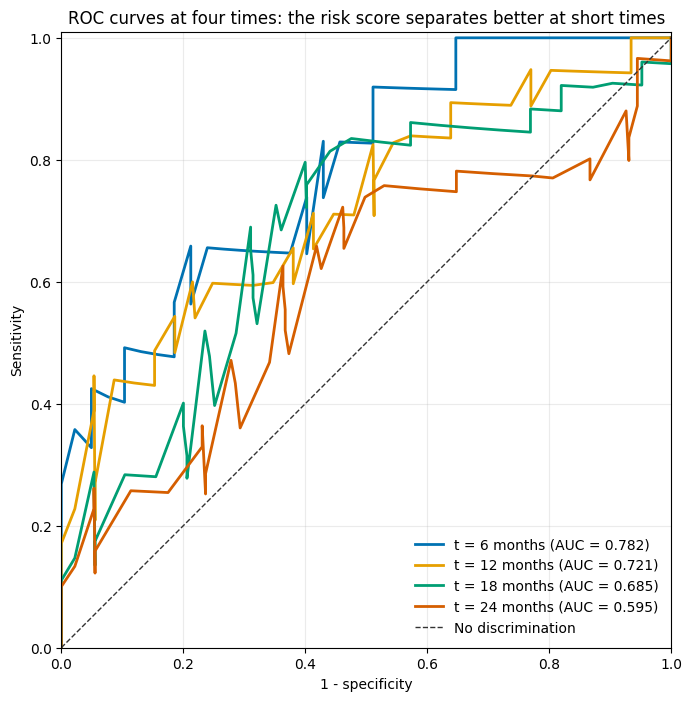

In [8]:
Times = [6,12,18,24]

Auc_list = []

fig, ax = plt.subplots(figsize=(8, 8))
for t, color in zip(Times, CLASS_COLORS):
    Auc_list.append(PlotRoc(ax, t, color=color, label='t = {t} months (AUC = {auc:.3f})'))
FormatRoc(ax, 'ROC curves at four times: the risk score separates better at short times')

Auc = pd.DataFrame({'AUC':Auc_list}, index=Times)

In [9]:
Auc.round(4)

,AUC
6,0.7824
12,0.7212
18,0.6848
24,0.5949


## The area under the curve as a function of time

The area under the curve (AUC) is the probability that, at time $t$, a patient who has died has a higher risk score than one who is still alive. It goes down with time: the variables measured at the beginning of the study say less and less about who is alive later.

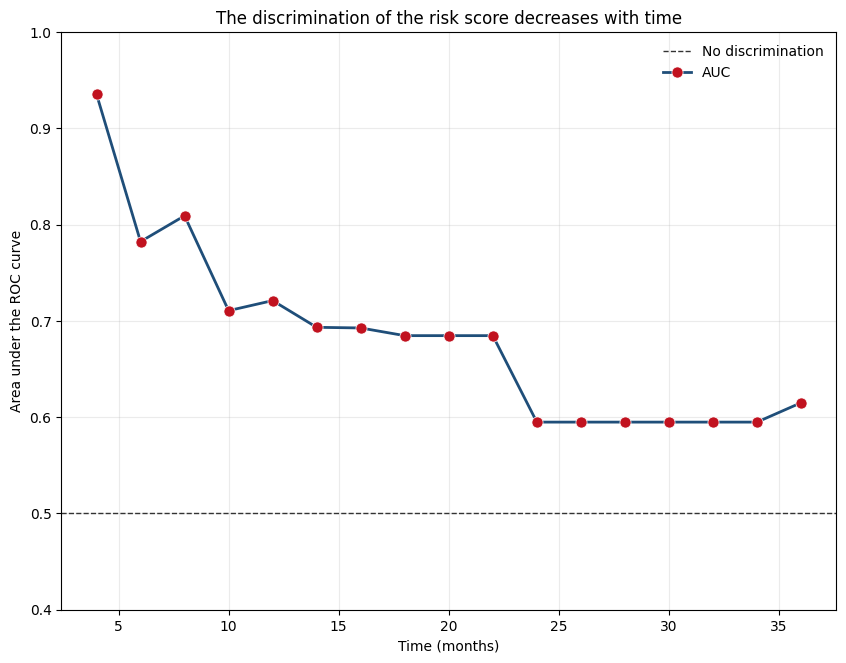

In [10]:
TimeGrid = np.arange(4, 37, 2)
AucGrid = [auc(Roc['1-Spec'], Roc['Sens']) for Roc in map(TimeDependROC, TimeGrid)]

plt.figure(figsize=(10, 7.5))
plt.axhline(0.5, color=ref_color, lw=1, ls='--', label='No discrimination')
plt.plot(TimeGrid, AucGrid, '-o', color=line_color, lw=2, markersize=8, markerfacecolor=point_color,
         markeredgecolor='white', markeredgewidth=0.5, label='AUC')
plt.xlabel('Time (months)')
plt.ylabel('Area under the ROC curve')
plt.ylim(0.4, 1)
plt.title('The discrimination of the risk score decreases with time')
plt.legend(loc='upper right', frameon=False)
plt.grid(True, alpha=0.25)